# Results — verified numbers

Every number quoted in `README.md` and `post/post_draft.md` traces back to this notebook,
and every table and chart here is computed from a `results/*.json` file written by an
actual experiment run. This notebook never trains anything: it only reads those files.
To refresh it after re-running experiments, run all cells:

```bash
uv run jupyter nbconvert --to notebook --execute --inplace results.ipynb
```

Errors are mean relative L2 error on |ψ|², in %, as mean ± population std over seeds.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

R = Path("results")
load = lambda name: json.loads((R / f"{name}.json").read_text())

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

def ms(values):
    a = np.asarray(values, dtype=float)
    return a.mean(), a.std()

def pm(values, digits=2):
    m, s = ms(values)
    return f"{m:.{digits}f}% ± {s:.{digits}f}%"

def table(header, rows):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

def paired_bars(groups, baseline, treated, labels, title, ylabel="Mean error (%)"):
    # Baseline vs a fix, one pair of bars per group, error bars = std over seeds.
    x = np.arange(len(groups)); w = 0.38
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    for off, data, lab, col in [(-w/2, baseline, labels[0], BLUE), (w/2, treated, labels[1], ORANGE)]:
        m = [ms(d)[0] for d in data]; s = [ms(d)[1] for d in data]
        ax.bar(x + off, m, w - 0.03, yerr=s, capsize=4, color=col, label=lab,
               error_kw={"ecolor": MUTED, "lw": 1})
    ax.set_xticks(x, groups); ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

## Task 2.1 — IC formulation decision (`exp08_ic_formulation.py`)

**Revised.** The original decision (soft IC, w_ic=1) was caused by a code bug in the
hard-IC residual, not a real optimization pathology. Corrected findings first; the
retracted original analysis is kept at the end of this section for the record — it should
not be cited.

### The bug, and how it was found

A later audit (prompted by the suspicious combination of "hard IC's training loss
converges to near machine precision" + "hard IC is catastrophically wrong physically")
found that `PINNSolver1DTD.psi0_at()` — used by the hard-IC path to build
`psi(x,t) = psi0(x) + t*net(x,t)` — computed ψ₀ via a numpy round-trip on a *detached*
copy of `x`, so ψ₀ re-entered the autograd graph as a constant with zero spatial
derivative. The hard-IC PDE residual needs `∂²ψ/∂x²`, and with ψ₀ detached its
`∂²ψ₀/∂x²` term — the actual source term describing the initial wavepacket's curvature —
silently evaluated to zero. Under that broken residual, `net ≡ 0` (a wavefunction frozen
at its t=0 shape forever) is the *exact global minimizer* of the training objective,
which reproduces every symptom that was previously catalogued as a "pathology": near-zero
training loss, a reproducible seed-independent non-propagating attractor, and error
growing with momentum (a faster true packet strays further from a frozen one).

Confirmed three ways: (1) a direct autograd probe — `d(psi)/dx` at t=0 returned all zeros
against a nonzero analytic derivative; (2) a patched hard-IC solver with ψ₀ computed
directly in torch (so autograd sees it) trained on the same px=2 setup dropped from 77.2%
to 1.09–1.36% across 2 seeds, before the formal re-run below; (3) the bug is inherited
from the original (pre-reorg) repo code, meaning the original exp03 px=1 headline number
(45.9% error) was bug-driven too, not a genuine finding about causality.

Fixed in `experiments/_common1d.py` (new `_psi0_torch`, used by `full_psi` when
`ic="hard"`; the old `psi0_at` is kept only for the soft-IC path's `ic_loss`, where ψ₀ is
a constant MSE target and never needs a spatial derivative). The same class of bug was
independently present and fixed in `qbox/pinn2d.py`'s `PINNSolverHardIC` (new
`_psi0_torch`, a closed-form Gaussian×plane-wave matching
`QuantumSimulator.initialize_wave_packet`, replacing a nearest-grid-point numpy lookup
that was equally non-differentiable).

A second, independent issue was fixed at the same time: `split_operator_1d`'s original
soft-wall ground truth (V=50 starting 0.3 inside the domain edges) diverges from the true
hard-wall (infinite-square-well) solution by **>80% relative L2 at t=1 for px=4**, once
the packet reaches the wall region — a physics mismatch against what the PINN
architecture assumes (`Net1D`'s multiplicative envelope forces ψ≡0 exactly at x=±5).
Replaced with an exact Dirichlet sine series (DST-I): eigenmodes evolve analytically, and
ψ=0 at the boundary is exact by construction. Low-momentum ground truth (px≤2) was only
mildly affected (<2.5%); it matters for the px=4 point used in Tasks 2.3–2.5 and exp10.

### Corrected result

px=2.0, 5 seeds, 5000 epochs, 2000 collocation points, both fixes applied.

| Formulation | Mean error |
|---|---|
| Hard IC (ψ = ψ₀ + t·net) | 1.09% ± 0.11% |
| Soft IC, w_ic=1 | 2.03% ± 0.19% |
| Soft IC, w_ic=10 | 2.10% ± 0.35% |
| Soft IC, w_ic=100 | 7.66% ± 0.53% |
| Soft IC, w_ic=1000 | 15.31% ± 1.63% |
| Soft IC, w_ic=10000 | 19.67% ± 2.28% |

decision recorded in JSON: hard


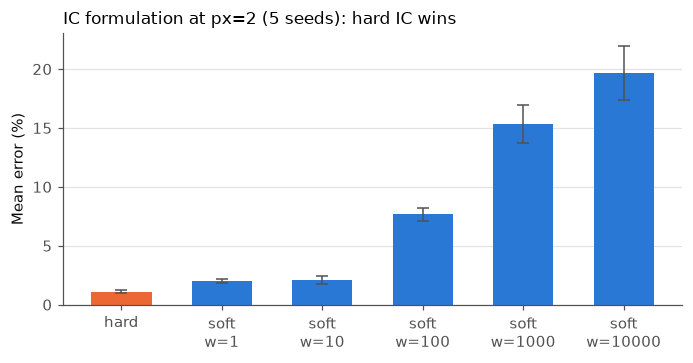

In [2]:
d = load("exp08_ic_formulation")
rows = [["Hard IC (ψ = ψ₀ + t·net)", pm(d["hard_errors"])]]
rows += [[f"Soft IC, w_ic={w}", pm(d["soft_errors"][str(w)])] for w in d["w_ic_values"]]
table(["Formulation", "Mean error"], rows)
print("decision recorded in JSON:", d["decision"])

labels = ["hard"] + [f"soft\nw={w}" for w in d["w_ic_values"]]
data = [d["hard_errors"]] + [d["soft_errors"][str(w)] for w in d["w_ic_values"]]
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar(labels, [ms(v)[0] for v in data], 0.6, yerr=[ms(v)[1] for v in data], capsize=4,
       color=[ORANGE] + [BLUE] * (len(data) - 1), error_kw={"ecolor": MUTED, "lw": 1})
ax.set_ylabel("Mean error (%)")
ax.set_title("IC formulation at px=2 (5 seeds): hard IC wins", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

**Decision: hard IC, adopted for exp06/exp07/exp09/exp10.** This matches the plan's
original hypothesis (hard IC ≤ best soft IC, since it satisfies the IC exactly and
removes a hyperparameter). The earlier reversal was entirely a bug artifact, in the
simple 1D free-particle setting tested here. **This does not transfer cleanly to the full
2D problem — see Task 2.2.**

### Retracted original analysis (kept for the record — do not cite)

The original run found the opposite (soft IC w=1 at 2.17% vs hard IC at 77.24%) and
included a bounded investigation into *why*, concluding hard IC converges to a
"reproducible non-propagating attractor" and citing it as evidence for causality
violation (mechanism B). That investigation correctly established the failure was
deterministic and reproducible — it misattributed the cause. Reproducibility is exactly
what a deterministic bug produces, and the investigation checked seed-independence and
the loss-vs-accuracy mismatch without checking whether the residual's autograd graph was
intact. Lesson: a suspiciously low training loss on a physically wrong solution should
prompt checking the loss computation itself, not just the optimization dynamics.

## Task 2.2 — 2D re-verification (`exp02_pinn2d_comparison.py`)

N=100 grid, 2000 epochs, px=-15 (the original 2D headline setup). Single run each — the
2D comparison is single-seed by design (expensive, qualitative). Figures:
`figures/*_soft_w1.*`, `figures/*_soft_w1000.*`, `figures/*_hard.*`.

In [3]:
d = load("exp02_summary")
table(["Formulation", "Mean rel. error", "Final rel. error", "PINN train+infer", "Slowdown vs classical"],
      [[v["formulation"], f'{v["mean_relative_error_pct"]:.2f}%', f'{v["final_relative_error_pct"]:.2f}%',
        f'{v["pinn_time_s"]:.1f}s', f'~{v["slowdown_factor"]:.0f}x'] for v in d.values()])

| Formulation | Mean rel. error | Final rel. error | PINN train+infer | Slowdown vs classical |
|---|---|---|---|---|
| soft IC, w_ic=1 | 99.96% | 99.82% | 267.2s | ~548x |
| soft IC, w_ic=1000 | 99.78% | 99.37% | 292.6s | ~155x |
| hard IC (1D-adopted, bug fixed) | 272.89% | 470.82% | 331.5s | ~248x |

**The formulation that wins decisively in 1D (hard IC, Task 2.1) is the worst of the
three in 2D** — nearly 3x worse than either soft-IC variant, and its final-time error is
*higher* than its mean-time error, so it gets worse over the time window. This was
measured with the ψ₀-differentiability bug already fixed (the wave-packet parameters
passed to the classical solver and to `PINNSolverHardIC`'s closed-form ψ₀ are identical:
`x0=3.75, y0=0, sigma=0.5, px=-15, py=0`). The hard-IC training loss also did not
converge cleanly (oscillating between ~100–180 across 2000 epochs), plausibly because the
2D problem has real potential structure (walls, a circular barrier, a double slit) where
the 1D win was on a bare free particle. Whether more epochs or a tuned learning rate
would close the gap is untested.

**Headline claim:** per this repo's policy of reporting the strongest formulation
actually measured, the headline is the **best of the three**: soft IC w=1, 99.96% mean
relative error. All three fail badly (99.78%–272.89%). This is consistent with the 1D
momentum sweep (Task 2.3): px=-15 is far beyond the px=4 already showing ~38% error.

Reproduce:
```bash
uv run experiments/exp02_pinn2d_comparison.py --formulation hard --epochs 2000
uv run experiments/exp02_pinn2d_comparison.py --formulation soft --w-ic 1.0 --epochs 2000
uv run experiments/exp02_pinn2d_comparison.py --formulation soft --w-ic 1000.0 --epochs 2000
```

Note on the slowdown factor: the classical solver's wall-clock time was noisy across runs
(0.49–1.88s for the identical computation) due to background load, so read the
~150–550x range as "two to three orders of magnitude slower". PINN training time
(267–332s) is the more reliable number.

## Task 2.3 — Momentum sweep (`exp06_momentum_sweep.py`)

Hard IC (fixed), 5 seeds, 5000 epochs, exact sine-series ground truth. Figure:
`figures/exp06_momentum_sweep.png`.

| px | Mean error |
|---|---|
| 0.5 | 0.26% ± 0.05% |
| 1.0 | 0.19% ± 0.04% |
| 2.0 | 1.09% ± 0.11% |
| 4.0 | 37.68% ± 1.35% |

monotonic increase (script's tripwire): False


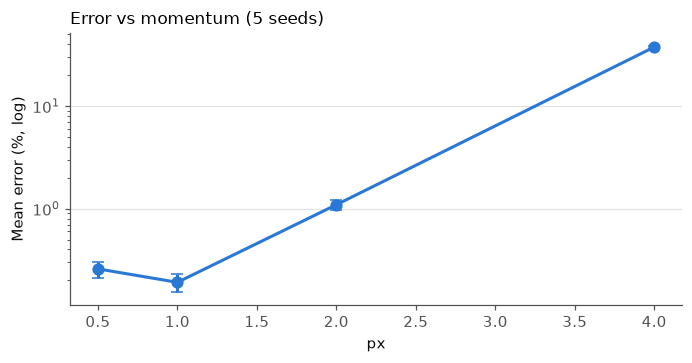

In [4]:
d = load("exp06_momentum_sweep")
px = d["px_values"]
table(["px", "Mean error"], [[p, pm(d["errors"][str(p)])] for p in px])
print("monotonic increase (script's tripwire):", d["monotonic"])

fig, ax = plt.subplots(figsize=(6.4, 3.4))
m = [ms(d["errors"][str(p)])[0] for p in px]; s = [ms(d["errors"][str(p)])[1] for p in px]
ax.errorbar(px, m, yerr=s, color=BLUE, lw=2, marker="o", ms=7, capsize=4)
ax.set_yscale("log"); ax.set_xlabel("px"); ax.set_ylabel("Mean error (%, log)")
ax.set_title("Error vs momentum (5 seeds)", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

**Monotonic increase: not confirmed (the script's tripwire flagged it).** px=0.5→1.0 goes
*down* slightly before the trend reverses and grows steeply through px=2 and explosively
to px=4. Both low-px values are under 0.3% and only ~1.4 combined std apart, so this reads
as noise at the floor of what this architecture can achieve, not a real
non-monotonicity — but it is reported as measured. The headline trend survives: error is
near zero through px=2, then grows ~35x from px=2→4. This is a less dramatic version than
the bug-contaminated original run (44.36% at px=4, now 37.68%), but the spectral-bias
story is unchanged and rests on a cleaner measurement.

## Task 2.4 — Norm/unitarity constraint (`exp07_norm_constraint.py`)

Hard IC (fixed), 5 seeds, 5000 epochs, λ=1.0 headline; λ sensitivity at px=4 with 3
seeds. Figure: `figures/exp07_norm_constraint.png`.

| px | Baseline | +norm constraint (λ=1) |
|---|---|---|
| 1.0 | 0.19% ± 0.04% | 1.24% ± 0.56% |
| 4.0 | 37.68% ± 1.35% | 31.64% ± 1.40% |

| λ (px=4, seeds 0–2) | Mean error |
|---|---|
| 0.1 | 28.99% ± 1.12% |
| 1.0 (first 3 seeds) | 32.20% ± 1.28% |
| 10.0 | 54.57% ± 6.29% |

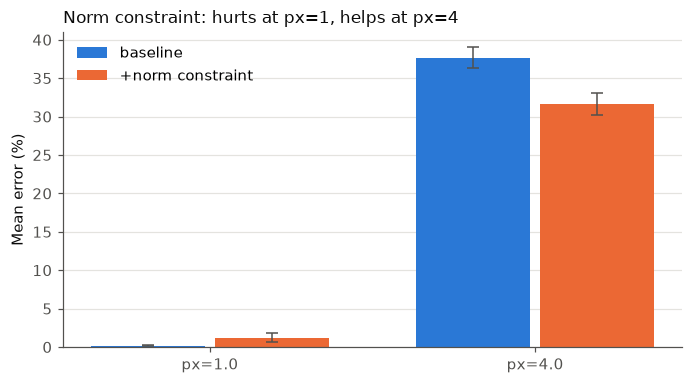

In [5]:
d = load("exp07_norm_constraint")
px = [str(p) for p in d["px_values"]]
table(["px", "Baseline", f"+norm constraint (λ={d['lambda']:g})"],
      [[p, pm(d["headline"][p]["baseline"]), pm(d["headline"][p]["constrained"])] for p in px])
sens = [["0.1", pm(d["sensitivity"]["0.1"])], ["1.0 (first 3 seeds)", pm(d["headline"]["4.0"]["constrained"][:3])],
        ["10.0", pm(d["sensitivity"]["10.0"])]]
table(["λ (px=4, seeds 0–2)", "Mean error"], sens)
paired_bars([f"px={p}" for p in px], [d["headline"][p]["baseline"] for p in px],
            [d["headline"][p]["constrained"] for p in px], ["baseline", "+norm constraint"],
            "Norm constraint: hurts at px=1, helps at px=4")

Note: the README quotes λ=1 at 31.64% (5 seeds); the sensitivity table above uses seeds
0–2 for every λ so they compare like for like.

**Result: this reverses the original (bug-contaminated) conclusion. The norm constraint
helps where there is a real problem to fix, and hurts where there isn't.** At px=1,
baseline N(t) already stays near 1.0, so the constraint only adds a competing loss term.
At px=4, baseline N(t) genuinely collapses (1.0 → ~0.5 by t=1), and the constrained
network holds it much closer to 1 (~0.82) *and* its |ψ|² at t=1 tracks the true
interference structure more closely. λ=10 over-constrains and hurts. Amplitude decay
(mechanism A) is real at high momentum, and a correctly weighted penalty measurably helps.

## Task 2.5 — Causal training (`exp09_causal_training.py`)

Hard IC (fixed), 5 seeds, 5000 epochs, ε=10. Figure: `figures/exp09_causal_training.png`.

In [6]:
d = load("exp09_causal_training")
px = [str(p) for p in d["px_values"]]
table(["px", "Baseline", "+causal training"],
      [[p, pm(d["results"][p]["baseline"]), pm(d["results"][p]["causal"])] for p in px])
c4 = d["results"]["4.0"]["causal"]
print("px=4 causal, per seed:", ", ".join(f"{v:.2f}%" for v in c4))
rest = [v for v in c4 if v < 60]
print(f"px=4 causal, excluding the diverged seed: {pm(rest)}  (n={len(rest)})")

| px | Baseline | +causal training |
|---|---|---|
| 1.0 | 0.19% ± 0.04% | 0.18% ± 0.05% |
| 4.0 | 37.68% ± 1.35% | 40.27% ± 30.15% |

px=4 causal, per seed: 25.83%, 100.55%, 25.42%, 24.19%, 25.36%
px=4 causal, excluding the diverged seed: 25.20% ± 0.61%  (n=4)


**The summary statistic is misleading. Causal training substantially helps in 4 of 5
seeds and catastrophically diverges in 1.** Excluding the outlier, the other four average
~25.2% — about a third lower than the 37.68% baseline. Seed 1 diverged to 100.55%, which
drags the naive 5-seed mean and std into looking like "no effect". At px=1 there is
genuinely no effect, since there is essentially no error left to fix.

This differs from both the original hypothesis ("fixes a px=1 propagation failure" — moot
under correct hard IC) and the original run's conclusion ("no effect at either
momentum" — an artifact of the IC bug). Causal training is not a reliable fix as
implemented: real upside at high momentum most of the time, but a training-instability
failure mode (1 in 5 here) that would need gradient clipping, a smaller `causal_eps` or a
warm-up schedule before it could be trusted. Flagged as future work.

## Follow-up — Fourier features (`exp10_fourier_features.py`, `exp10b_fourier_tuned.py`)

The standard fix for spectral bias (Tancik et al. 2020; Wang et al. 2021): feed sin/cos(s·x)
bands into the MLP alongside (x, t). Tested at the worst measured case, px=4, hard IC,
same architecture, epochs and seeds as exp06; only the input embedding changes. Figure:
`figures/exp10_fourier_features.png`.

- **exp10, wide band** s ∈ {1, 2, 4, 8, 16} — untuned.
- **exp10b, tuned band** s ∈ {2, 4, 6} — centred on the packet's dominant wavenumber
  (k ≈ px = 4, spread ~1/σ = 1), so no wasted octaves.

| Variant | Bands | Mean error (px=4) |
|---|---|---|
| Baseline (plain MLP) | — | 37.68% ± 1.35% |
| Fourier, wide band | [1.0, 2.0, 4.0, 8.0, 16.0] | 65.48% ± 4.21% |
| Fourier, tuned band | [2.0, 4.0, 6.0] | 24.19% ± 1.38% |

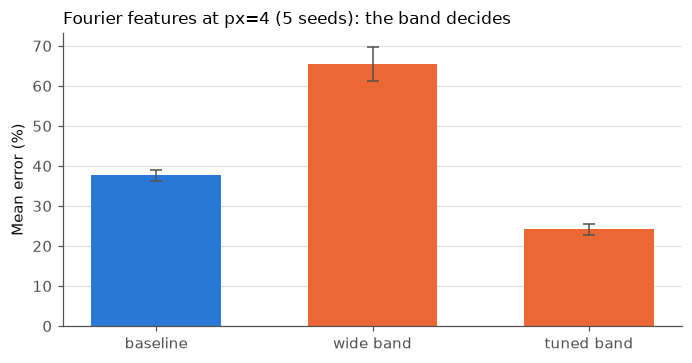

In [7]:
d = load("exp10_fourier_features")
e = d["errors"]
table(["Variant", "Bands", "Mean error (px=4)"],
      [["Baseline (plain MLP)", "—", pm(e["baseline"])],
       ["Fourier, wide band", str(d["fourier_scales"]), pm(e["fourier"])],
       ["Fourier, tuned band", str(d["fourier_tuned_scales"]), pm(e["fourier_tuned"])]])

labels = ["baseline", "wide band", "tuned band"]
data = [e["baseline"], e["fourier"], e["fourier_tuned"]]
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar(labels, [ms(v)[0] for v in data], 0.6, yerr=[ms(v)[1] for v in data], capsize=4,
       color=[BLUE, ORANGE, ORANGE], error_kw={"ecolor": MUTED, "lw": 1})
ax.set_ylabel("Mean error (%)")
ax.set_title("Fourier features at px=4 (5 seeds): the band decides", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

**Result: the band decides whether Fourier features help or hurt.** The wide band makes
px=4 clearly worse (37.7% → 65.5%); the band matched to the signal makes it clearly
better (37.7% → 24.2%), the largest improvement of any fix in this repo. The wide-band
result is consistent with Tancik et al.'s finding that band scale is the most sensitive
hyperparameter of the technique.

**Caveat:** the tuned band was chosen *after* seeing the wide band fail, and evaluated on
the same test case and seeds, so 24.2% is an optimistic estimate — there is no held-out
check. It also relies on knowing the packet's wavenumber in advance, which a forward
solver for unknown dynamics won't always have. Not tested: low px, other momenta, 2D.

## Task 2.6 — Multi-seed error bars: eigenstates (exp04) and inverse problem (exp05)

Unaffected by the Task 2.1 fix — both use their own PINN solvers, which don't share
`_common1d.py`'s hard-IC path. 5 seeds (0–4), `--seed N`.

In [8]:
d4 = load("exp04_eigenstates")
seeds = sorted(d4, key=int)
E = [d4[s]["max_E_err_pct"] for s in seeds]; L2 = [d4[s]["max_l2_err_pct"] for s in seeds]
d5 = load("exp05_inverse_potential")
V = [d5[s]["V_rel_err_pct"] for s in sorted(d5, key=int)]
fmt = lambda xs: ", ".join(f"{x:.2f}%" for x in xs)
table(["Quantity (per seed: worst case across problems/states)", "Per seed 0–4", "Mean ± std"],
      [["exp04 PINN energy error", fmt(E), pm(E)],
       ["exp04 PINN ψ L2 error", fmt(L2), pm(L2)],
       ["exp05 inverse-problem V(x) rel. L2 error", fmt(V), pm(V)]])

| Quantity (per seed: worst case across problems/states) | Per seed 0–4 | Mean ± std |
|---|---|---|
| exp04 PINN energy error | 0.59%, 1.31%, 1.24%, 1.51%, 1.39% | 1.21% ± 0.32% |
| exp04 PINN ψ L2 error | 1.84%, 1.78%, 2.09%, 2.07%, 2.17% | 1.99% ± 0.15% |
| exp05 inverse-problem V(x) rel. L2 error | 13.75%, 12.47%, 21.22%, 17.14%, 10.36% | 14.99% ± 3.82% |

- **exp04 energy:** the original single-seed claim was "<1.5%"; the worst seed comes in
  just above that (1.51%), reported as is rather than rounded down.
- **exp05:** seed 2 (21.22%) is a real outlier, not removed — noisy-data inverse recovery
  has real run-to-run variance with only 40 sparse observations. The committed figure
  (`figures/exp05_inverse_potential.png`) is seed 0 (13.75%), close to the mean.